# Chapter 9 · Project: fixing the rain twin (OpenMRG, Gothenburg)
**Level: Expert** · ~30 min to read, 15 min to run (mostly the 500 m grid) · 2D · *Applied project, part 3*

Chapter 8 ended with two losses. At the 10 held-out gauges, plain IDW of the links made a better
map of the rain *now* than the twin did (correlation 0.69 against 0.59). And for forecasts of
the links, the twin only tied persistence on average, because on 25 July persistence stayed
excellent for a full hour.

This chapter works out why, and tries five fixes. Two of them work; three do not, and we keep
those in because a failed fix tells you what the problem is *not*.

**Rules, so that the scores stay honest**
* The gauges are never assimilated and nothing is tuned on them. They only score.
* The gauges are split into two halves (A, B). A fix counts only if it helps on both.
* Forecasts are scored against what the links read later, and every choice the forecast
  makes uses only data that had arrived by then.

| Section | Question |
|---|---|
| 1 | Where does the twin's error come from? |
| 2 | Fixes that do not help: finer grid, radar as a sensor, learned growth, link offsets in the state |
| 3 | Fix for the map: twin plus a local correction at the links |
| 4 | Fix for the forecast: carry each link's miss forward, with a fade time the twin picks itself |

In [1]:
import sys, time; sys.path.insert(0, "..")
import warnings; warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np
import matplotlib.pyplot as plt
from dtwin import viz
from raintwin import RainTwin, ResidualBlend, line_idw, path_operator
from raintwin.openmrg import OpenMRG
viz.set_style()

d = OpenMRG()
L = d.links
EVENTS = [("2015-07-25 04:00", "2015-07-25 11:00"), ("2015-07-26 00:00", "2015-07-26 07:00"),
          ("2015-07-28 13:00", "2015-07-28 19:00"), ("2015-07-29 00:00", "2015-07-29 10:00")]
GA, GB = np.arange(0, 10, 2), np.arange(1, 10, 2)        # the two gauge halves
print("gauge half A:", d.gauges["id"][GA])
print("gauge half B:", d.gauges["id"][GB])

gauge half A: ['Jarn' 'Bergsj' 'Chalm' 'Barl' 'Lbom']
gauge half B: ['Torp' 'Torsl' 'Tole' 'Drakeg' 'Askim']


## The experiment loop
One function runs a storm with any of the options this chapter tests. It records, every
5 minutes:
* the twin mean, the hybrid map (section 3) and line IDW, read at the gauges;
* the twin's **miss** at every link, `y − H·mean`: what the map fails to explain;
* every 15 minutes, a 1-hour forecast of the links: the pure twin, and the blend from
  section 4.

In [2]:
def corr(a, b):
    a, b = np.ravel(a), np.ravel(b)
    ok = np.isfinite(a) & np.isfinite(b)
    return np.corrcoef(a[ok], b[ok])[0, 1]


def run_event(start, end, factor=1, radar=False, rad_err=(1.0, 0.5), keep_maps=False, **kw):
    y, times = d.link_rain(start, end)
    g, _ = d.gauge_rain(start, end)
    rad, _ = d.radar(start, end)
    T = min(len(y), len(g), len(rad))
    x, yc = d.fine_grid(factor)
    X, Y = np.meshgrid(x, yc)
    Hg = path_operator(d.gauges["x"], d.gauges["y"], d.gauges["x"], d.gauges["y"], x, yc)
    opts = dict(noise_cells=3.0 * factor, seed=1)          # noise scale stays 6 km on any grid
    opts.update(kw)
    tw = RainTwin(x, yc, L, **opts)
    if radar:                                               # every other radar cell, with a bias
        RX, RY = np.meshgrid(d.x, d.y)
        sel = ((np.arange(d.y.size)[:, None] % 2 == 0) & (np.arange(d.x.size)[None] % 2 == 0)).ravel()
        tw.add_obs("radar", RX.ravel()[sel], RY.ravel()[sel], RX.ravel()[sel], RY.ravel()[sel],
                   *rad_err, bias=True, H=d.radar_operator(factor)[np.where(sel)[0]])
    tw.initialise(np.full(X.shape, max(np.nanmean(y[0]), 0.1)), background=0.3, vel_std=20)
    blend = ResidualBlend()
    o = {k: [] for k in ("twin_g", "hyb_g", "idw_g", "gauge", "miss", "fit", "G", "bias", "maps")}
    o["fc"] = []
    for k in range(T):
        if k:
            tw.forecast(5 / 60)
        st = tw.analysis(y[k], extra={"radar": rad[k].ravel()[sel]} if radar else None)
        hyb = tw.now_map(y[k])
        idw = line_idw(y[k], L["xa"], L["ya"], L["xb"], L["yb"], X, Y)
        o["twin_g"].append(Hg @ tw.mean.ravel()); o["hyb_g"].append(Hg @ hyb.ravel())
        o["idw_g"].append(Hg @ idw.ravel()); o["gauge"].append(g[k])
        o["miss"].append(y[k] - tw.link_readings(tw.mean)); o["fit"].append(st.get("fit_corr", np.nan))
        o["G"].append(tw.G.mean()); o["bias"].append(tw.B["radar"].mean() if radar else np.nan)
        if keep_maps:
            o["maps"].append((tw.mean, hyb, idw))
        blend.verify(k, y[k])
        if k >= 6 and k % 3 == 0 and k + 12 < T:
            P = tw.link_readings(tw.predict(12, 5 / 60)[0])
            o["fc"].append(dict(k=k, twin=P, blend=blend.issue(k, P, o["miss"][-1]), tau=blend.tau,
                                miss=o["miss"][-1]))
    for key in o:
        if key not in ("fc", "maps"):
            o[key] = np.array(o[key])
    o.update(y=y[:T], times=times[:T], T=T, V=tw.V.mean(0), radar=rad[:T])
    return o


def gauge_scores(r, key, cols=slice(None)):
    return corr(r[key][6:, cols], r["gauge"][6:, cols])          # skip the 30-minute spin-up


def nowcast(r, key, h):
    """Correlation of a forecast at lead h (steps) with what the links read later."""
    if key == "persistence":
        a = np.concatenate([r["y"][f["k"]] for f in r["fc"]])
    else:
        a = np.concatenate([f[key][h - 1] for f in r["fc"]])
    return corr(a, np.concatenate([r["y"][f["k"] + h] for f in r["fc"]]))


t0 = time.time()
base = {s[:10]: run_event(s, e, keep_maps=True) for s, e in EVENTS}
print(f"baseline (Chapter 8's twin), 4 storms in {time.time()-t0:.0f}s")
for ev, r in base.items():
    print(f"  {ev}: gauges twin {gauge_scores(r, 'twin_g'):.2f}  IDW {gauge_scores(r, 'idw_g'):.2f};  "
          f"fit to links {np.nanmean(r['fit'][6:]):.2f}")

baseline (Chapter 8's twin), 4 storms in 42s
  2015-07-25: gauges twin 0.62  IDW 0.60;  fit to links 0.36
  2015-07-26: gauges twin 0.73  IDW 0.77;  fit to links 0.74
  2015-07-28: gauges twin 0.40  IDW 0.72;  fit to links 0.67
  2015-07-29: gauges twin 0.60  IDW 0.65;  fit to links 0.66


Same numbers as Chapter 8: the twin is behind IDW at the gauges, worst on 28 July. On 25 July it
fits its own links badly (0.36), even though that storm is the slowest and steadiest of the four.

## 1. Where the error comes from
If the miss `y − H·mean` were random noise, it would change from one 5-minute step to the next.
Here is how long it lasts: the correlation of each link's miss with its own miss some minutes later.

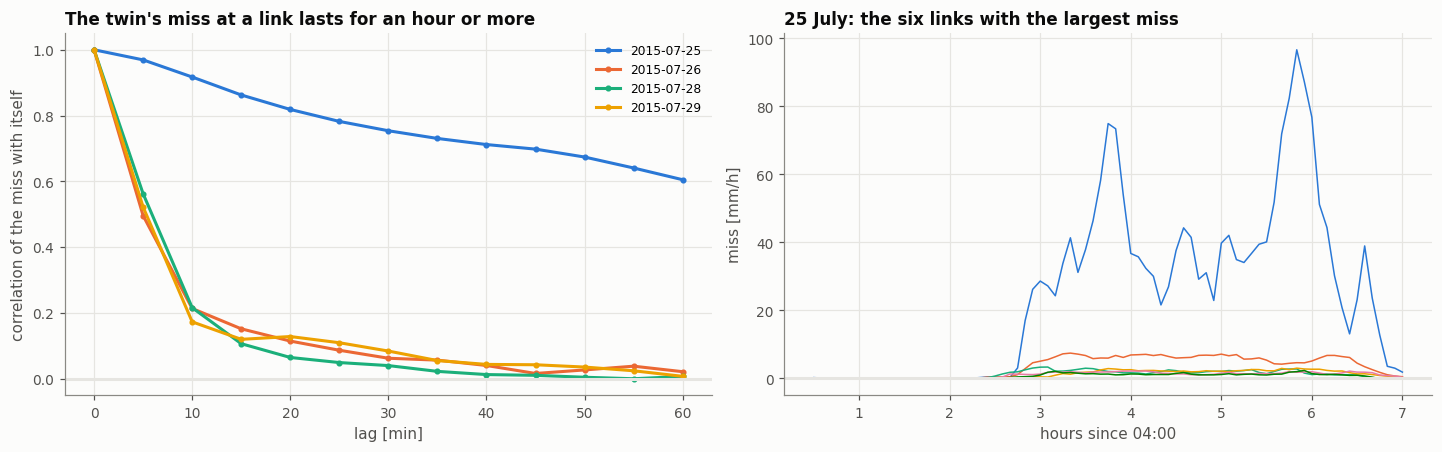

In [3]:
lags = np.arange(0, 13)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
for j, (ev, r) in enumerate(base.items()):
    M = r["miss"][6:]
    ac = [corr(M[: len(M) - l], M[l:]) for l in lags]
    axes[0].plot(lags * 5, ac, "o-", ms=3, color=viz.SERIES[j], label=ev)
axes[0].axhline(0, color=viz.GRID)
axes[0].set(xlabel="lag [min]", ylabel="correlation of the miss with itself",
            title="The twin's miss at a link lasts for an hour or more")
axes[0].legend(fontsize=8)
r = base["2015-07-25"]
M = r["miss"][6:]
top = np.argsort(-np.nanmean(np.abs(M), 0))[:6]
tt = np.arange(6, r["T"]) * 5 / 60
for j, i in enumerate(top):
    axes[1].plot(tt, M[:, i], lw=1, color=viz.SERIES[j])
axes[1].axhline(0, color=viz.GRID)
axes[1].set(xlabel="hours since 04:00", ylabel="miss [mm/h]",
            title="25 July: the six links with the largest miss")
viz.save(fig, "09_miss_memory.png")
plt.show()

The miss has a long memory, longest on 25 July. Individual links sit above or below the map for
hours. Some of that is rain the map smoothed away. Much of it, in light steady rain, is the link
itself: wet antennas, a baseline set a bit off, a path through a heavier shower than its
neighbours. Persistence keeps every link's quirk; the map cannot, because two links 500 m apart
that disagree by 1 mm/h cannot both be fitted by a smooth field.

So the question for every fix below is: does it help the twin explain a quirk that stays with
one link?

## 2. Four fixes that do not help
**(a) A finer grid.** Many links are shorter than a 2 km cell. Perhaps they fight over a cell.
Try 1 km and 500 m cells over the same area.

In [4]:
def summary(runs):
    g = np.mean([gauge_scores(r, "twin_g") for r in runs.values()])
    f = np.mean([np.nanmean(r["fit"][6:]) for r in runs.values()])
    n15 = np.mean([nowcast(r, "twin", 3) for r in runs.values()])
    n30 = np.mean([nowcast(r, "twin", 6) for r in runs.values()])
    return g, f, n15, n30

variants = {"baseline: 2 km": base}
for name, kw in [("1 km grid", dict(factor=2)), ("500 m grid", dict(factor=4)),
                 ("radar as a sensor (bias learned)", dict(radar=True)),
                 ("learned growth / decay", dict(growth=True, q_growth=0.01)),
                 ("link offsets in the state", dict(link_bias_gain=0.05))]:
    t0 = time.time()
    variants[name] = {s[:10]: run_event(s, e, **kw) for s, e in EVENTS}
    print(f"{name}: {time.time()-t0:.0f}s")

print(f"\n{'variant':34s} {'gauges':>7s} {'fit':>6s} {'15 min':>7s} {'30 min':>7s}")
for name, runs in variants.items():
    g, f, n15, n30 = summary(runs)
    print(f"{name:34s} {g:7.2f} {f:6.2f} {n15:7.2f} {n30:7.2f}")
pers = [np.mean([nowcast(r, "persistence", h) for r in base.values()]) for h in (3, 6)]
print(f"{'persistence (for reference)':34s} {'':7s} {'':6s} {pers[0]:7.2f} {pers[1]:7.2f}")
print("\nlearned growth rate at the end of each storm [1/h]:",
      [round(float(r["G"][-1]), 2) for r in variants["learned growth / decay"].values()])
print("learned radar bias at the end of each storm (radar / twin):",
      [round(float(np.exp(r["bias"][-1])), 2) for r in variants["radar as a sensor (bias learned)"].values()])

1 km grid: 161s


500 m grid: 573s


radar as a sensor (bias learned): 85s


learned growth / decay: 63s


link offsets in the state: 55s

variant                             gauges    fit  15 min  30 min
baseline: 2 km                        0.59   0.60    0.36    0.24
1 km grid                             0.60   0.59    0.35    0.21
500 m grid                            0.57   0.59    0.34    0.21
radar as a sensor (bias learned)      0.59   0.59    0.36    0.24
learned growth / decay                0.59   0.61    0.31    0.14
link offsets in the state             0.53   0.63    0.42    0.29
persistence (for reference)                          0.38    0.27

learned growth rate at the end of each storm [1/h]: [0.8, 0.31, 0.12, 0.41]
learned radar bias at the end of each storm (radar / twin): [1.03, 0.55, 0.62, 0.77]


Read the table from the top.

* **Finer grids change almost nothing.** The fit to the links stays near 0.6 on every grid. Cell
  size was not the limit; the ensemble and the 6 km noise scale decide how much detail the twin
  can hold, and the quirks above are not detail a smooth field can carry.
* **Radar as a sensor** (every other 2 km cell, error 1 mm/h + 50 %, with a learned
  multiplicative bias) is neutral: no score moves by more than 0.01. With errors that large the
  radar adds little, and Chapter 8 showed it agrees poorly with the links anyway.
* **Learned growth** makes the forecast worse. The filter pushes the growth rate positive in every
  storm (printed above), because a positive rate is the cheapest way to raise the field where links read more
  than the map. A one-number growth rate for the whole domain is the wrong model.
* **Link offsets in the state** (each link gets an offset, nudged 5 % of the way toward its
  miss every step) is the interesting failure. Look at it per storm:

In [5]:
off = variants["link offsets in the state"]
print(f"{'storm':12s} {'gauges: base':>13s} {'offsets':>8s}   {'15 min: base':>13s} {'offsets':>8s} {'persist.':>9s}")
for ev in base:
    print(f"{ev:12s} {gauge_scores(base[ev], 'twin_g'):13.2f} {gauge_scores(off[ev], 'twin_g'):8.2f}   "
          f"{nowcast(base[ev], 'twin', 3):13.2f} {nowcast(off[ev], 'twin', 3):8.2f} "
          f"{nowcast(base[ev], 'persistence', 3):9.2f}")

storm         gauges: base  offsets    15 min: base  offsets  persist.
2015-07-25            0.62     0.63            0.31     0.84      0.86
2015-07-26            0.73     0.65            0.52     0.39      0.29
2015-07-28            0.40     0.36            0.21     0.14      0.14
2015-07-29            0.60     0.49            0.42     0.31      0.23


On 25 July the offsets lift the 15-minute forecast from about 0.3 to about 0.8. So the diagnosis in
section 1 was right: the quirks are there and they persist. But in the three moving storms both
the map and the forecast get worse. Moving rain sits over a link for a while; the offset soaks part of
it up, and that rain then disappears from the map.

That suggests the fix: **keep the map clean, and use each link's quirk only where it matters,
which is at that link.**

## 3. The map: twin plus a local correction
The *now* map is the twin mean plus an IDW of the twin's miss at the links, spread no further
than 3 km from any link (`RainTwin.now_map`). Near a link it honours the link like IDW does.
Far from links it is the twin, with motion and memory behind it. The twin's state is not
changed, so nothing leaks into the forecast.

In [6]:
print(f"{'storm':12s} {'twin':>6s} {'hybrid':>7s} {'IDW':>6s}   {'half A: hybrid':>15s} {'IDW':>6s}   {'half B: hybrid':>15s} {'IDW':>6s}")
tab = []
for ev, r in base.items():
    row = [gauge_scores(r, k) for k in ("twin_g", "hyb_g", "idw_g")]
    row += [gauge_scores(r, k, GA) for k in ("hyb_g", "idw_g")] + [gauge_scores(r, k, GB) for k in ("hyb_g", "idw_g")]
    tab.append(row)
    print(f"{ev:12s} {row[0]:6.2f} {row[1]:7.2f} {row[2]:6.2f}   {row[3]:15.2f} {row[4]:6.2f}   {row[5]:15.2f} {row[6]:6.2f}")
tab = np.array(tab).mean(0)
print(f"{'mean':12s} {tab[0]:6.2f} {tab[1]:7.2f} {tab[2]:6.2f}   {tab[3]:15.2f} {tab[4]:6.2f}   {tab[5]:15.2f} {tab[6]:6.2f}")

storm          twin  hybrid    IDW    half A: hybrid    IDW    half B: hybrid    IDW
2015-07-25     0.62    0.61   0.60              0.65   0.66              0.60   0.57
2015-07-26     0.73    0.79   0.77              0.79   0.77              0.84   0.81
2015-07-28     0.40    0.73   0.72              0.77   0.77              0.69   0.66
2015-07-29     0.60    0.68   0.65              0.75   0.74              0.51   0.46
mean           0.59    0.70   0.69              0.74   0.73              0.66   0.63


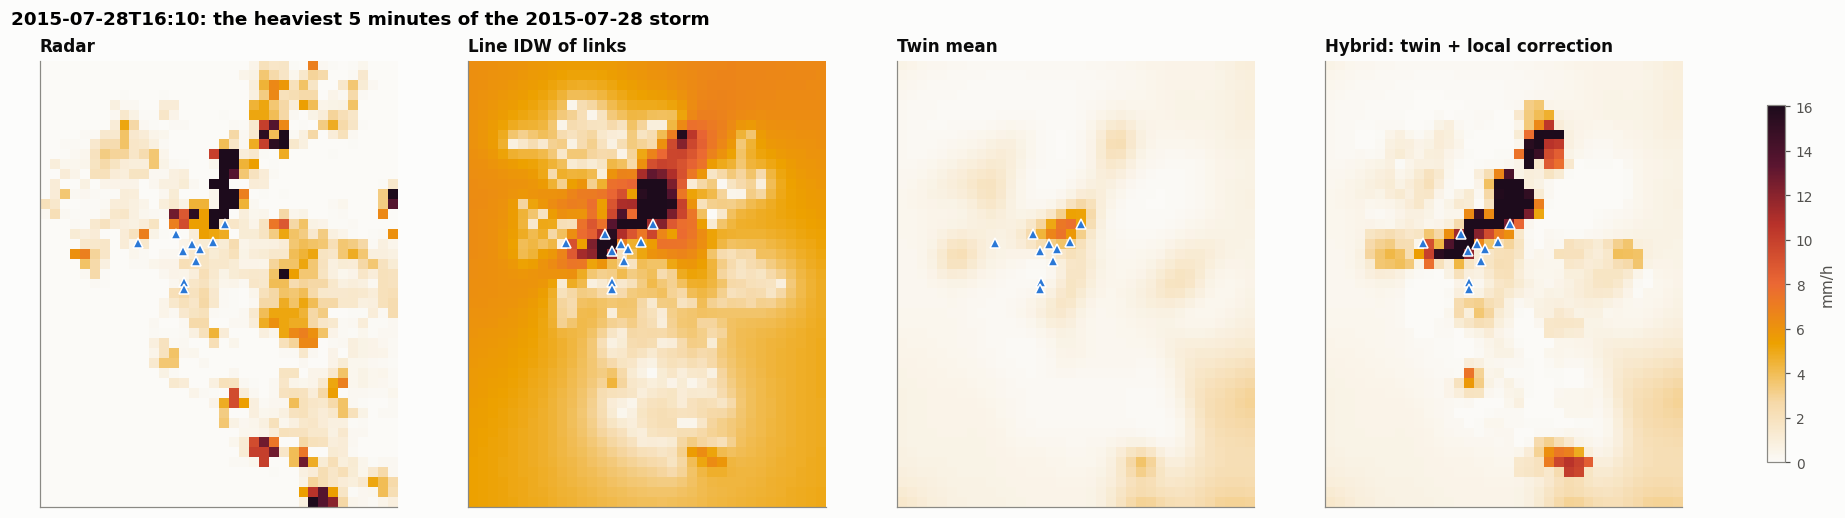

In [7]:
ev = "2015-07-28"
r = base[ev]
k = int(np.argmax(np.nanmean(r["y"], 1)))
tw_map, hyb_map, idw_map = r["maps"][k]
vm = np.nanpercentile(idw_map, 99)
ext = (d.x[0] - 1, d.x[-1] + 1, d.y[0] - 1, d.y[-1] + 1)
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6), constrained_layout=True)
for ax, (F, ttl) in zip(axes, [(r["radar"][k], "Radar"), (idw_map, "Line IDW of links"),
                               (tw_map, "Twin mean"), (hyb_map, "Hybrid: twin + local correction")]):
    ax.grid(False)
    im = ax.imshow(F, origin="lower", cmap=viz.FIELD, vmin=0, vmax=vm, extent=ext)
    ax.plot(d.gauges["x"], d.gauges["y"], "^", color=viz.BLUE, ms=6, mec="white")
    ax.set(title=ttl, xticks=[], yticks=[])
plt.colorbar(im, ax=axes, shrink=0.8, label="mm/h")
fig.suptitle(f"{str(r['times'][k])[:16]}: the heaviest 5 minutes of the {ev} storm", x=0.02, ha="left",
             fontweight="semibold")
viz.save(fig, "09_hybrid_maps.png")
plt.show()

The hybrid is ahead of IDW in every storm and on both gauge halves on average (0.74 vs 0.73 on A,
0.66 vs 0.63 on B). On single storm halves it sometimes ties or trails by 0.01, so call it a small
but consistent edge. The big change is against the twin alone, on 28 July: 0.40 becomes 0.73. The twin's smooth field
missed the small heavy cells; the local correction puts them back where links saw them.

The margin over IDW is small. Inside a dense network IDW is already close to what the links
can tell you. What the hybrid adds is everything IDW does not have: a spread map, a motion
vector, and a forecast, all from the same state.

## 4. The forecast: carry each link's miss forward
A link forecast at lead *h* is the twin's forecast plus the link's current miss, faded:

$$\hat y_i(t+h) = (H\,\bar R_{t+h})_i + e^{-h/\tau}\,\big(y_i(t) - (H\,\bar R_t)_i\big)$$

τ = 0 is the pure twin. τ = ∞ keeps the whole miss, which at short leads is almost persistence.
The best τ depends on the storm, so `ResidualBlend` lets the twin choose. It keeps every candidate
τ in {0, 15 min, 30 min, 1 h, 2 h, ∞}. Each time a forecast's 15-minute lead comes due, it scores
all of them, and it uses the one with the lowest recent error for the next forecast. This is the
twin checking its own forecasts against the data as they arrive; nothing is fitted offline.

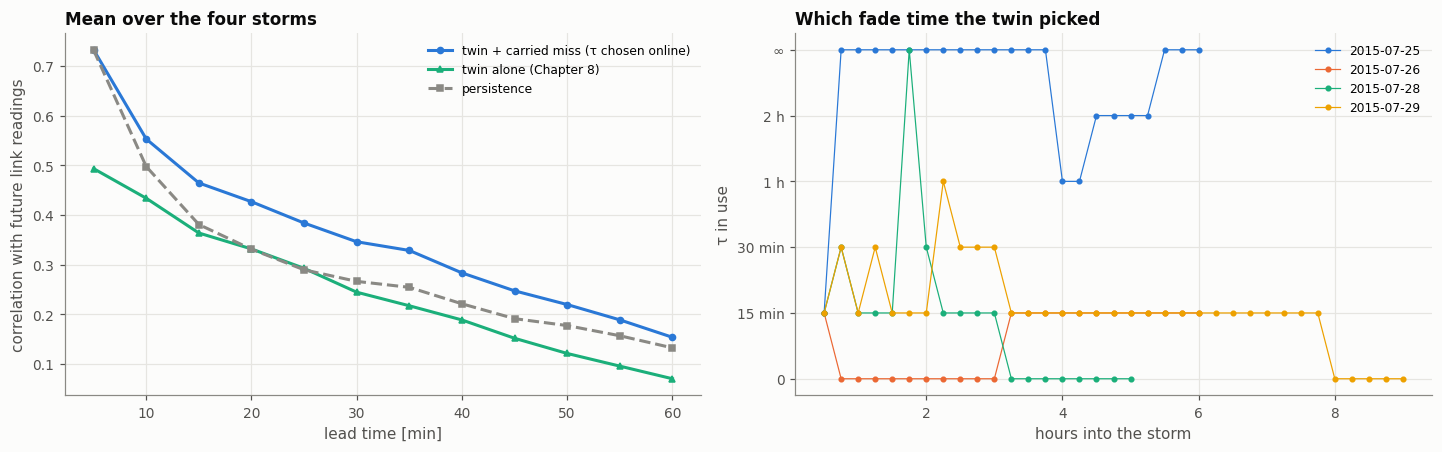

storm         15 min: blend   twin  persist.    30 min: blend   twin  persist.
2015-07-25             0.86   0.31      0.86             0.71   0.23      0.73
2015-07-26             0.48   0.52      0.29             0.35   0.38      0.14
2015-07-28             0.18   0.21      0.14             0.05   0.09      0.03
2015-07-29             0.34   0.42      0.23             0.27   0.28      0.16
mean at  5 min: blend 0.73   twin 0.49   persistence 0.73
mean at 15 min: blend 0.46   twin 0.36   persistence 0.38
mean at 30 min: blend 0.35   twin 0.24   persistence 0.27
mean at 60 min: blend 0.15   twin 0.07   persistence 0.13


In [8]:
hz = np.arange(1, 13)
curves = {key: np.array([[nowcast(r, key, h) for h in hz] for r in base.values()])
          for key in ("twin", "blend", "persistence")}
fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
for key, col, mk, lab in [("blend", viz.TWIN, "o-", "twin + carried miss (τ chosen online)"),
                          ("twin", viz.AQUA, "^-", "twin alone (Chapter 8)"),
                          ("persistence", viz.MUTED, "s--", "persistence")]:
    axes[0].plot(hz * 5, curves[key].mean(0), mk, color=col, ms=4, label=lab)
axes[0].set(xlabel="lead time [min]", ylabel="correlation with future link readings",
            title="Mean over the four storms")
axes[0].legend(fontsize=8)
TAUS = ResidualBlend().taus
for j, (ev, r) in enumerate(base.items()):
    picks = [TAUS.index(f["tau"]) for f in r["fc"]]
    axes[1].plot(np.array([f["k"] for f in r["fc"]]) * 5 / 60, picks, "o-", ms=3, lw=0.8,
                 color=viz.SERIES[j], label=ev)
axes[1].set_yticks(range(len(TAUS)), ["0", "15 min", "30 min", "1 h", "2 h", "∞"])
axes[1].set(xlabel="hours into the storm", ylabel="τ in use", title="Which fade time the twin picked")
axes[1].legend(fontsize=8)
viz.save(fig, "09_nowcast.png")
plt.show()

print(f"{'storm':12s} {'15 min: blend':>14s} {'twin':>6s} {'persist.':>9s}   {'30 min: blend':>14s} {'twin':>6s} {'persist.':>9s}")
for j, ev in enumerate(base):
    print(f"{ev:12s} {curves['blend'][j, 2]:14.2f} {curves['twin'][j, 2]:6.2f} {curves['persistence'][j, 2]:9.2f}   "
          f"{curves['blend'][j, 5]:14.2f} {curves['twin'][j, 5]:6.2f} {curves['persistence'][j, 5]:9.2f}")
for h in (1, 3, 6, 12):
    print(f"mean at {h*5:2d} min: blend {curves['blend'][:, h-1].mean():.2f}   twin {curves['twin'][:, h-1].mean():.2f}"
          f"   persistence {curves['persistence'][:, h-1].mean():.2f}")

On average the blend now beats persistence at every lead from 15 minutes to an hour (0.46 vs 0.38
at 15 minutes, 0.35 vs 0.27 at 30), and it ties at 5 minutes. The right panel shows how. On 25 July the twin soon learns to keep the miss for a long
time (τ = 2 h or ∞), so its forecast follows persistence where persistence is right. In the moving
storms it mostly picks τ = 0 or 15 minutes: the miss there is moving rain, and the twin's own
advection is the better guide.

The choice has a price. In the three moving storms the pure twin is a little better than the
blend (at 15 minutes 0.52 vs 0.48, 0.21 vs 0.18, 0.42 vs 0.34), because the blend spends some
forecasts on a τ that was right a few cycles earlier. On 25 July the blend gains 0.55 over the
twin and ties persistence. That trade is why the average goes up so much. Sixty minutes is still weak for every method; a single
storm velocity and a fixed decay are not enough for an hour of convective rain.

## Conclusions
| | Chapter 8 | Chapter 9 |
|---|---|---|
| Map at the gauges (mean corr) | twin 0.59, IDW 0.69 | **hybrid 0.70**, a small edge over IDW in all four storms and on both gauge halves |
| 15-min link forecast | twin 0.36, persistence 0.38 | **blend 0.46** |
| 30-min link forecast | twin 0.24, persistence 0.27 | **blend 0.35** |
| What limited the twin | not known | link quirks that persist for hours, which a smooth field cannot fit |
| Did not help | | finer grid, radar as a sensor, one global growth rate, offsets inside the state |

The general point is about where a sensor's own error should live. Putting each link's quirk into
the state made the map worse; handling it at the link, as a correction to the map shown and to the
forecast of that link, made both better. The twin's state stays a model of the rain, and the
sensor model stays with the sensor.

**Next: New York (Chapter 10).** OpenMesh has 359 links and its own personal weather stations, and
`pcpn_maps` already produces link rain rates there. Scoring would be against MRMS radar and ASOS
gauges over 52 storms, which is enough data to test a growth model per region rather than one
number for the whole domain.